# Football player strike rate analysis

## Introduction
This is an attempt at recreating the analysis of football scoring ability, from the book __Bayesian Analysis with Python__

I had considerable difficulty with this exercise, as explained below. I'm being to see that Bayesian analysis requires both deep theoretical knowledge, and knowledge on driving the available software.

The book's example Notebook is at
[https://github.com/aloctavodia/BAP3/blob/main/code_updated/Chp_03.ipynb]

## Implementation

### Imports

In [1]:
import pathlib

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import preliz as pz
import pymc as pm

--------------

## Read data

Held as a CSV file, with _pandas_ knows how to read

In [2]:
path = pathlib.Path("data/football_players.csv")
df = pd.read_csv(path)
df.head()

,name,position,goals,shots
0,Aaron Connolly,FW,5,59
1,Aaron Cresswell,DF,4,69
2,Aaron Hunt,MF,3,30
3,Aaron Lennon,MF,1,5
4,Aaron Leya Iseka,FW,10,76


-------------------

## Explore data

We look at some summary statistics, and create a new column _igps_ for individual goals per shot.  Note that the mean _igps_ does __not__ match the value of  $total\_goals/total\_shots$.  Means of ratios don't necessarily equal the ratio of the sum of numerators over the sum of the denominators

In [3]:
total_shots = df["shots"].sum()
total_goals = df["goals"].sum()

print(f" Average goals for shot = {round(float(total_goals/total_shots), 2)}")

 Average goals for shot = 0.11


In [4]:
for pos in df["position"].unique():
    pos_goals = round(float(df[df["position"] == pos]["goals"].sum()))
    pos_shots = round(float(df[df["position"] == pos]["shots"].sum()))
    print(f"For position {pos},   average goals for shot = {pos_goals/pos_shots:4.2}")
# end for

For position FW,   average goals for shot = 0.14
For position DF,   average goals for shot = 0.082
For position MF,   average goals for shot = 0.087
For position GK,   average goals for shot = 0.043


In [5]:
df["igps"] = df["goals"] / df["shots"]
print(f'Average individual strike rate {df["igps"].mean():4.2}')
df["igps"].describe()

Average individual strike rate 0.088


count    2535.000000
mean        0.087594
std         0.076213
min         0.000000
25%         0.032258
50%         0.081633
75%         0.126624
max         1.000000
Name: igps, dtype: float64

Look at position column - we have four playing positions in the dataset.

In [6]:
df["position"].unique()

<ArrowStringArray>
['FW', 'DF', 'MF', 'GK']
Length: 4, dtype: str

Set up a dict that maps short code to long name (mostly for plotting)

In [7]:
position_long_name = {
    "FW": "Forward",
    "DF": "Defender",
    "MF": "Midfield",
    "GK": "Goal Keeper",
}

----------------------

## Plot data

We create some initial plots, just to get a sense of the data

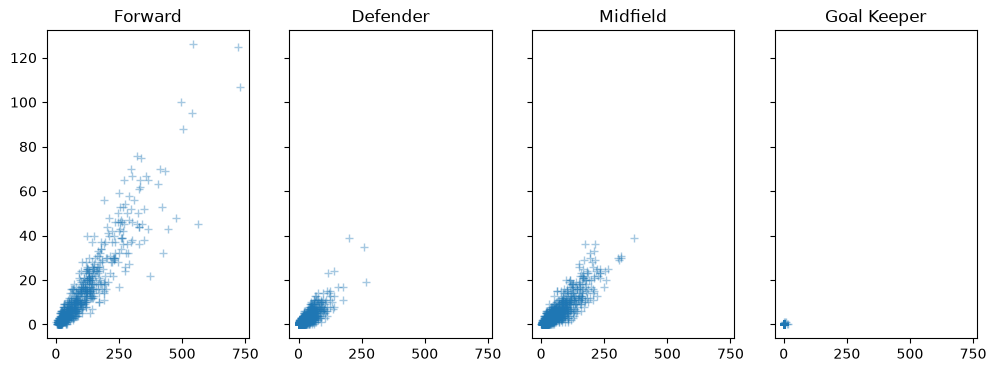

In [8]:
fig, ax = plt.subplots(
    nrows=1,
    ncols=len(df["position"].unique()),
    figsize=(12, 4),
    sharey=True,
    sharex=True,
)
for i, pos in enumerate(df["position"].unique()):
    ax[i].plot(
        df[df["position"] == pos]["shots"],
        df[df["position"] == pos]["goals"],
        "+",
        alpha=0.4,
    )
    ax[i].set_title(position_long_name[pos])
# end for

-----------------------------

Look at the distribution of the individual strike rate, first for all players, and then for players in the four positions

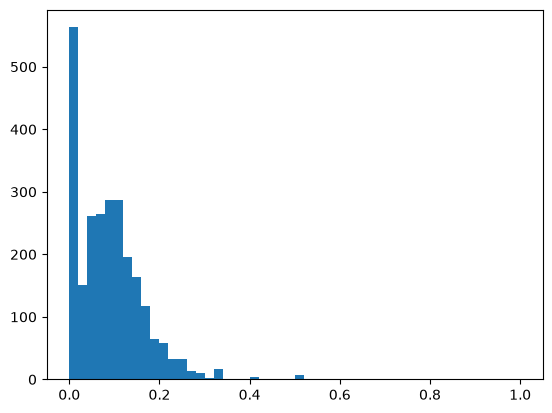

In [9]:
_ = plt.hist(
    df["igps"],
    bins=50,
)

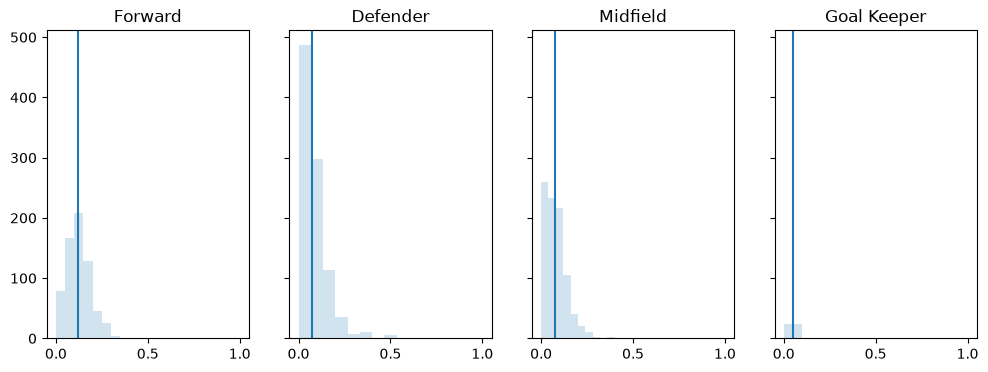

In [10]:
fig, ax = plt.subplots(
    nrows=1,
    ncols=len(df["position"].unique()),
    figsize=(12, 4),
    sharey=True,
    sharex=True,
)

for i, pos in enumerate(df["position"].unique()):
    m = df[df["position"] == pos]["igps"].mean()

    ax[i].hist(
        df[df["position"] == pos]["igps"],
        alpha=0.2,
        label=pos,
    )
    ax[i].set_title(position_long_name[pos])
    ax[i].axvline(m, label="mean")

# end for

------------------------

### Convert _position_ to be a category

This make subsequent code much easier

In [11]:
df["position"] = df["position"].astype("category")

In [12]:
df.head()

,name,position,goals,shots,igps
0,Aaron Connolly,FW,5,59,0.084746
1,Aaron Cresswell,DF,4,69,0.057971
2,Aaron Hunt,MF,3,30,0.100000
3,Aaron Lennon,MF,1,5,0.200000
4,Aaron Leya Iseka,FW,10,76,0.131579


In [13]:
df.dtypes

name             str
position    category
goals          int64
shots          int64
igps         float64
dtype: object

In [14]:
df["position"].head().cat.codes

0    1
1    0
2    3
3    3
4    1
dtype: int8

In [15]:
df["position"].cat.categories

Index(['DF', 'FW', 'GK', 'MF'], dtype='str')

In [16]:
cats = df["position"].cat.categories

Look up position code of first player in dataframe

In [17]:
cats[df["position"].cat.codes[0]]

'FW'

Count of positions

In [18]:
n_positions = len(df["position"].cat.categories)
n_positions

4

Count of players

In [19]:
n_players = len(df)
n_players

2682

In [20]:
position_codes = df["position"].cat.categories

position_codes.values

<ArrowStringArray>
['DF', 'FW', 'GK', 'MF']
Length: 4, dtype: str

In [21]:
coords = {"position": position_codes.values}
coords

{'position': <ArrowStringArray>
 ['DF', 'FW', 'GK', 'MF']
 Length: 4, dtype: str}

---------------------------------------

### Define helper functions

- _plot_dist_ plots PyMC distribution on a Matplotlib axes

- _beta_ab_to_mn_ converts Beta distribution parameters alpha, beta to mu, nu

- _beta_mn_to_ab_ converts Beta distribution parameters Mu, nu to alpha, beta

In [22]:
def plot_dist(dist, ax):
    """
    plot_dist: plots PyMC distribution on a Matplotlib axes
    """
    draws = pm.draw(dist, draws=5000, random_seed=42)
    ax.hist(
        draws,
        alpha=0.1,
        density=True,
        bins=100,
        label="PyMC draws",
    )
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.set_title("PyMC Distribution Draw")
    ax.legend()


# end plot_dist

In [23]:
def beta_ab_to_mn(alpha, beta):
    """
    beta_ab_to_mn: converts beta distribution parameters
    """

    nu = alpha + beta
    mu = alpha / nu
    return (mu, nu)


# end beta_ab_to_mn


def beta_mn_to_ab(mu, nu):
    """
    beta_ab_to_mn: converts beta distribution parameters
    """

    alpha = mu * nu
    beta = (1 - mu) * nu
    return (alpha, beta)


# end beta_mn_to_ab(mu, nu)

As an example, we plot a Beta distribution parameterized by _alpha_ , _beta_, and then replot with computed _mu_, _nu_.  Plots are identical

 mu=0.2857142857142857 nu=7


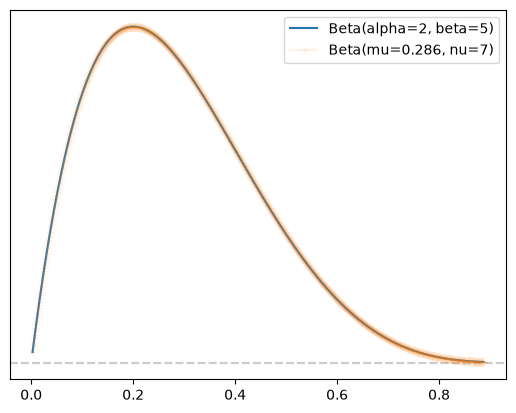

In [24]:
alpha = 2  # shape
beta = 5  # scale

# plot using preliz
ax = pz.Beta(alpha=alpha, beta=beta).plot_pdf()

mu, nu = beta_ab_to_mn(alpha, beta)
pz.Beta(mu=mu, nu=nu).plot_pdf(ax=ax, alpha=0.1, marker="+")

ax.legend()
print(f" {mu=} {nu=}")

###  Explaining _mu_, _nu_

We set the _mu_, mean of the distribution to be 0.4, and then change _nu_.  As _nu_ gets bigger, the distribution is more concentrated around the mean.


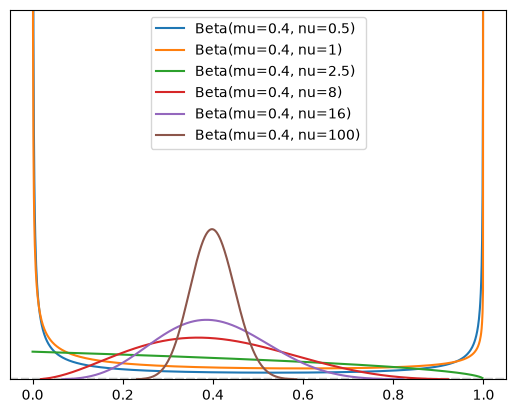

In [25]:
fig, ax = plt.subplots()
mu = 0.4
for nu in [0.5, 1, 1 / 0.4, 8, 16, 100]:
    pz.Beta(mu=mu, nu=float(nu)).plot_pdf(ax=ax)
# end for
ax.legend()
_ = ax.set_ylim(0, 20)

#### Example of Beta using _alpha_ and _beta_

Means = ['  0.5', '  0.5', ' 0.29']


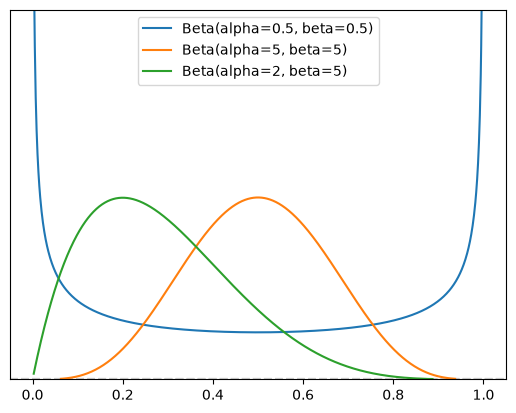

In [26]:
alphas = [0.5, 5.0, 2.0]
betas = [0.5, 5.0, 5.0]
for alpha, beta in zip(alphas, betas):
    ax = pz.Beta(alpha, beta).plot_pdf()
# end for
ax.legend()
ax.set_ylim(0, 5)
means = [f" {alpha/(alpha+beta):4.2}" for alpha, beta in zip(alphas, betas)]
print(f"Means = {means}")

------------------------------------

## Building the model

We build the model:

At the bottom level, we model the players strike rate as a Binomial (toss-of-the-coin).  This assumes each attempt at goal is independent (no learning effect, no _hot hand_ (or in this case, _hot foot_).  Each player gets an individual model.  What we are looking for is the probability distribution of the _strike_rate_, given the data of shots and goals.

As example, below is the plotted distribution for goals scored, by a player with strike rate $0.2$, given 100 shots at goal.  However, in our model we don't want a single guess / estimate of the strike rate, we want a distribution so we can see how certain / uncertain we are

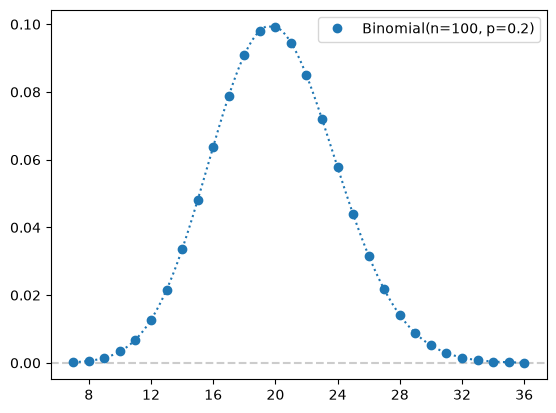

In [27]:
# model goals scored out of 100 shots, with strike_rate = 0.2
n_shots = 100
strike_rate = 0.2
ax = pz.Binomial(n=n_shots, p=strike_rate).plot_pdf()
ax.legend()

------------------------
## Prior for strike rate

As a start point, we assume that the distribution of the strike rate is a Beta distribution.  Beta distributions are common in Bayesian analysis - nice analytic properties, and by careful choice of parameters that can model a wide variety of our initial beliefs in the distribution of a parameter (in this case, strike rate)


## Initial model with common strike rate for all players

### Illustrate Beta distribution

Choose a realistic prior distribution, somewhere around 0.1 strike rate.

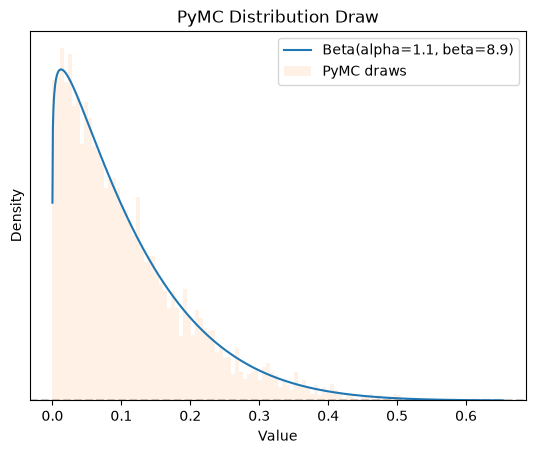

In [28]:
mu = 0.11

nu = 10

alpha, beta = beta_mn_to_ab(mu, nu)

# plot using preliz
ax = pz.Beta(alpha=alpha, beta=beta).plot_pdf()

# plot what PyMC sees
dist = pm.Beta.dist(alpha=alpha, beta=beta)
plot_dist(dist, ax)

------------------------------

### Build and run model

Here _theta_ is our estimate of the global common strike rate.  We start by assuming the distribution is a Beta, and then update this distribution based upon the data we have

In [29]:
with pm.Model() as model_1:
    theta = pm.Beta("theta", mu=mu, nu=nu)
    _ = pm.Binomial("gs", n=df["shots"].values, p=theta, observed=df["goals"].values)
    idata_1 = pm.sample()
# end with

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
NUTS[nutpie]: [theta]


Output()

The posterior distribution for _theta_, and the trace seem OK  (i.e. the random sampling probably worked)

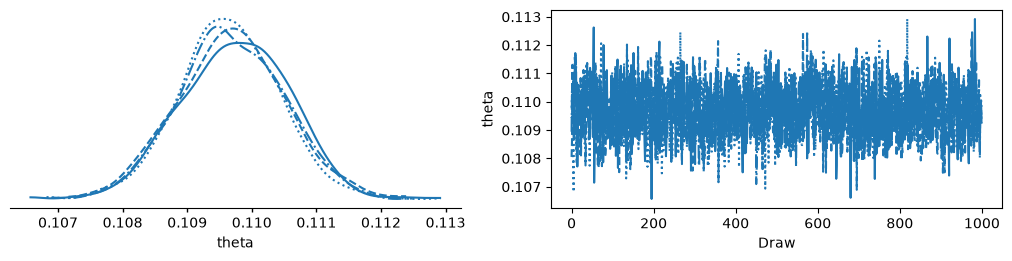

In [30]:
az.plot_trace_dist(idata_1, var_names=["theta"])

Summary seem ok (as expected)

In [31]:
az.summary(
    idata_1,
    kind="stats",
    ci_kind="hdi",
    var_names=["theta"],
)

,mean,sd,hdi89_lb,hdi89_ub
theta,0.11,0.00082,0.11,0.11


No problems reported with the sampling

In [32]:
problems = az.diagnose(idata_1)

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


#### Get posterior data

Get data to draw the prior distribution, as seen by model

#### Build posterior sample

In [33]:
with model_1:
    pm.sample_posterior_predictive(idata_1, extend_inferencedata=True)
    prior_idata1 = pm.sample_prior_predictive(1000)
    idata_1.update(prior_idata1)
# end with

Sampling: [gs]


Output()

Sampling: [gs, theta]


### Plotting distributions

the _plot_prior_posterior_ call is not very useful, but we can see that the density of the posterior is concentrated
around the group mean.  This high density dominates the plot, and makes the prior look flat

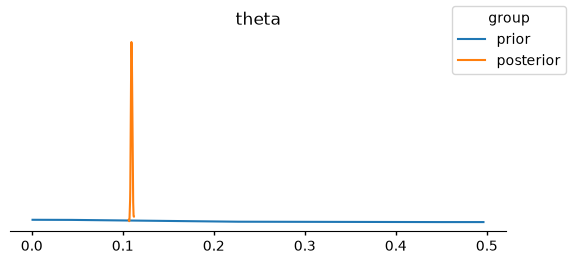

In [34]:
az.plot_prior_posterior(
    idata_1,
    var_names=["theta"],
)

Lets do two plots (so different Y axis scales).  We can see the mean hasn't changed much, but the uncertainty is reduced

Text(0.5, 1.0, 'theta posterior')

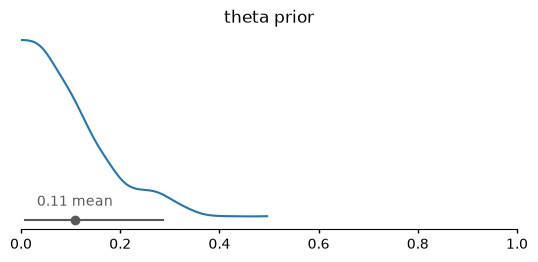

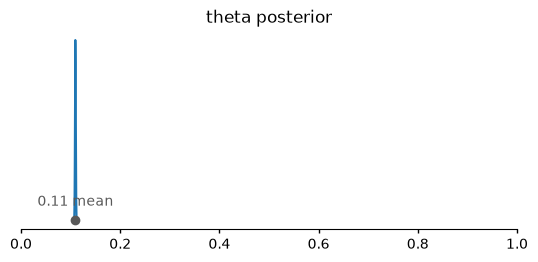

In [35]:
# Plot Prior in the first subplot
pc1 = az.plot_dist(
    idata_1,
    var_names=["theta"],
    group="prior",
)
pc1.get_viz("plot", "theta").set_xlim(0, 1)
pc1.get_viz("plot", "theta").set_title("theta prior")

# Plot Posterior in the second subplot
pc2 = az.plot_dist(
    idata_1,
    var_names=["theta"],
    group="posterior",
)
pc2.get_viz("plot", "theta").set_xlim(0, 1)
pc2.get_viz("plot", "theta").set_title("theta posterior")

Finally, just plot the posterior

Text(0.5, 1.0, 'theta posterior')

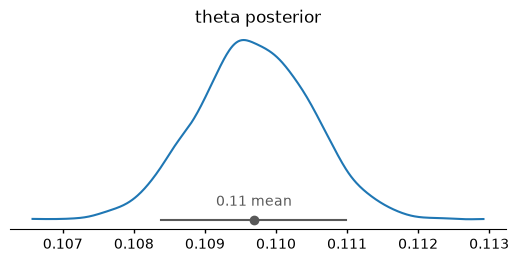

In [36]:
pc2 = az.plot_dist(
    idata_1,
    var_names=["theta"],
    group="posterior",
)
pc2.get_viz("plot", "theta").set_title("theta posterior")

-----------------
## Compute analytic solution

We can actually check our solution, by computing the analytic solution. Compare the plot below with the plot  above

In [37]:
print(f"Prior alpha = {alpha}, beta = {beta}")

Prior alpha = 1.1, beta = 8.9


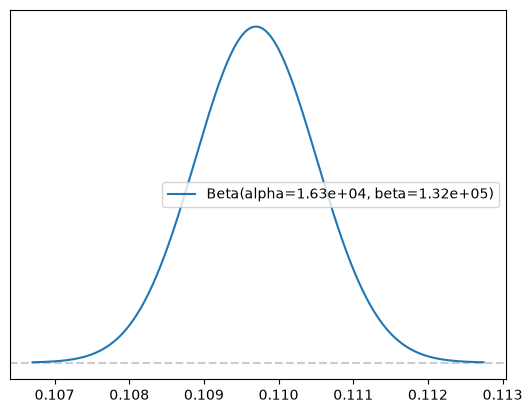

In [38]:
new_alpha = alpha + total_goals
new_beta = beta + total_shots - total_goals

# plot using preliz

ax = pz.Beta(alpha=new_alpha, beta=new_beta).plot_pdf()
ax.legend()

The _mu_, _nu_ Beta parameters for our analytic solution.  Note the very large _nu_ value - a very concentrated distribution 

In [39]:
new_mu, new_nu = beta_ab_to_mn(new_alpha, new_beta)
new_mu, new_nu

(np.float64(0.10970187031324878), np.float64(148157.0))

-----------------------------------------

## Model different positions

The next iteration of the model assumes that players in different positions have a different posterior distribution of strike rate.

In [40]:
position_codes = df.position.cat.categories
position_codes

Index(['DF', 'FW', 'GK', 'MF'], dtype='str')

In [41]:
position_index = df.position.cat.codes.values
position_index

array([1, 0, 3, ..., 3, 3, 0], shape=(2682,), dtype=int8)

Create a dict that PyMC will use

In [42]:
coords = {"pos": position_codes}

---------------

### Prior distribution of mean strike rate (common for all positions)

Because we now want to build multiple strike rate Beta distributions, we have to decide how the parameters of these distributions are to be themselves distributed.

We start by saying the mean of each strike rate distribution is distributed like a Beta (mean = .11, concentration = 10)
Then we say the concentration of each strike rate distribution is distributed like a Gamma (mean = 125, standard deviation = 50)

See the graphs below.

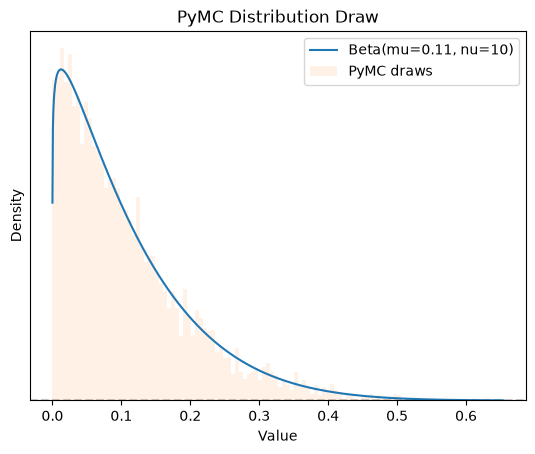

In [43]:
ax = pz.Beta(mu=0.11, nu=10).plot_pdf()
dist = pm.Beta.dist(mu=0.11, nu=10)
plot_dist(dist, ax)

#### Prior distribution for concentration (big means very concentrated)

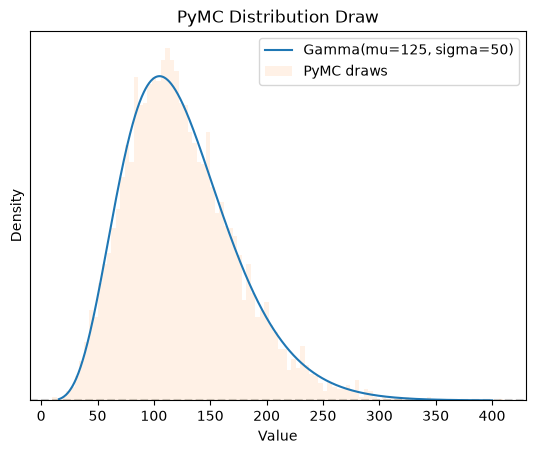

In [44]:
ax = pz.Gamma(mu=125, sigma=50).plot_pdf()
dist = pm.Gamma.dist(mu=125, sigma=50)
plot_dist(dist, ax)

We start by computing the (same) prior for the  _mu_, _nu_ for each position.  Then we can compute the _alpha_, _beta_ distributions for each position.  Then we can use the PyMC BetaBinomial distribution to update each _mu_, _nu_, from the observed data for players in each position.

If we weren't using the Beta for our prior, this wouldn't work

In [45]:
with pm.Model(coords=coords) as model_2:
    mu = 0.11
    nu = 10

    mu_p = pm.Beta("mu_p", mu=mu, nu=nu, dims="pos")
    nu_p = pm.Gamma("nu_p", mu=125, sigma=50, dims="pos")

    alpha = mu_p * nu_p
    beta = (1 - mu_p) * nu_p

    # update initial prior distributions based upon goals and shots data
    _ = pm.BetaBinomial(
        "gs",
        n=df["shots"].values,
        alpha=alpha[position_index],
        beta=beta[position_index],
        observed=df["goals"].values,
    )
    idata_2 = pm.sample()
# end with

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
NUTS[nutpie]: [mu_p, nu_p]


Output()

--------------------

### Review model outputs

Graph our model

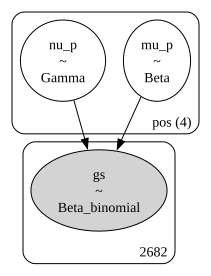

In [46]:
pm.model_to_graphviz(model_2)

In [47]:
problems = az.diagnose(idata_2)

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
R-hat values satisfactory for all parameters.

Processing complete, no problems detected.


Get posterior data for plotting

In [48]:
with model_2:
    pm.sample_posterior_predictive(idata_2, extend_inferencedata=True)
    prior_idata2 = pm.sample_prior_predictive(1000)
    idata_2.update(prior_idata2)
# end with

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\pytensor\link\numba\dispatch\basic.py:234: UserWarning: Numba will use object mode to run beta_binomial_rv{"(),(),()->()"}'s perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(
Sampling: [gs]


Output()

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\pytensor\link\numba\dispatch\basic.py:234: UserWarning: Numba will use object mode to run beta_binomial_rv{"(),(),()->()"}'s perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(
Sampling: [gs, mu_p, nu_p]


The warning message above means the run might have been slower than usual

    PyTensor tries to compile a custom random variable, like a Beta-Binomial distribution, but cannot fully translate the underlying code into a fast, optimized C 

-------------------
### Visualize results

Plot out mean strike rate for each position.  Note we have to dive down the the Matplotlib level to change plot titles

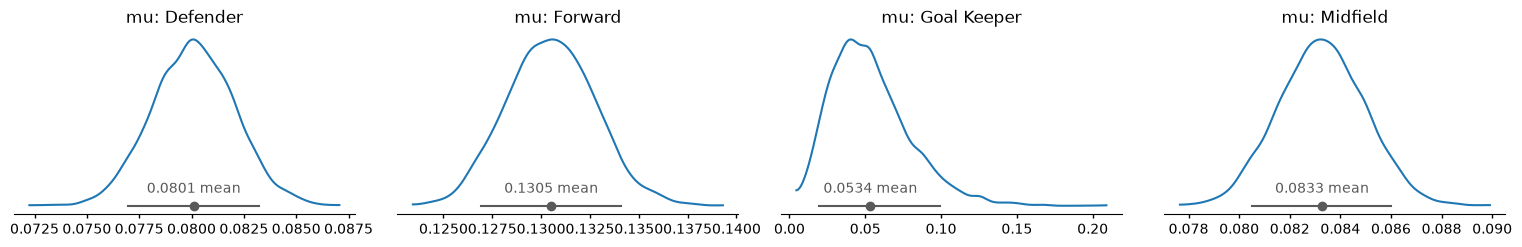

In [49]:
pc = az.plot_dist(
    idata_2,
    var_names=["mu_p"],
    visuals={"point_estimate_text": {"round_to": 4}},
)

for i, pos in enumerate(["DF", "FW", "GK", "MF"]):
    pc.viz.figure.item().axes[i].set_title("mu: " + position_long_name[pos])
plt.tight_layout()

Plot the concentration for each strike rate distribution

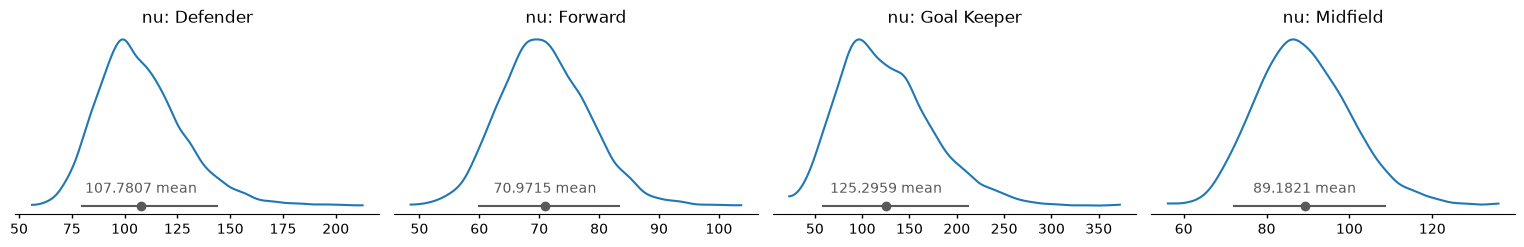

In [50]:
pc = az.plot_dist(
    idata_2,
    var_names=["nu_p"],
    visuals={"point_estimate_text": {"round_to": 4}},
)

for i, pos in enumerate(["DF", "FW", "GK", "MF"]):
    pc.viz.figure.item().axes[i].set_title("nu: " + position_long_name[pos])
plt.tight_layout()

------------------

### Comparing positions

We generate a number of ways of looking at our model

First: sampled posterior

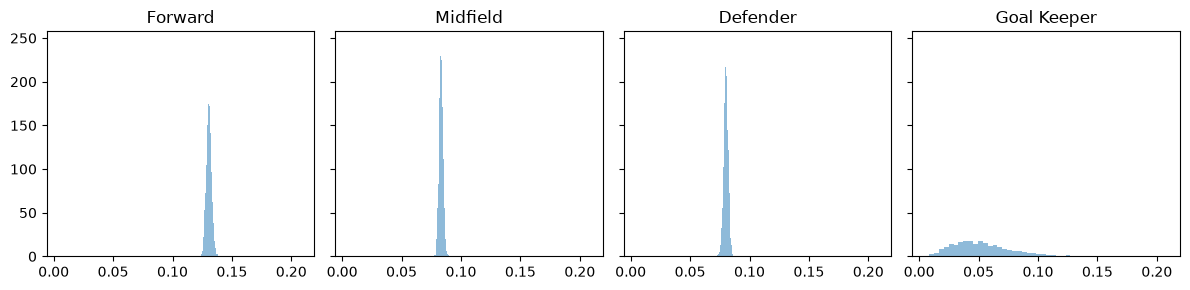

In [51]:
# posterior of strike rate by position (mu_p)
fig, ax = plt.subplots(1, 4, figsize=(12, 3), sharex=True, sharey=True)
for a, pos in zip(ax, ["FW", "MF", "DF", "GK"]):
    a.hist(
        idata_2.posterior["mu_p"].sel(pos=pos).values.ravel(),
        bins=50,
        density=True,
        alpha=0.5,
    )
    a.set_title(position_long_name[pos])
# end for
plt.tight_layout()

Next: a Forest Plot

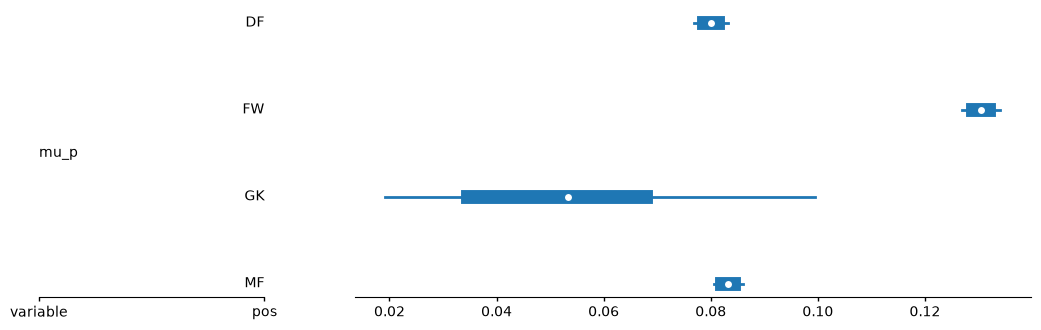

In [52]:
az.plot_forest(
    idata_2,
    var_names=["mu_p"],
    combined=True,
    visuals={
        "trunk": {"width": 10},  # Set width of the inner interval line
        "twig": {"width": 2},  # Set width of the outer interval line
    },
)

Next: a Ridge Plot

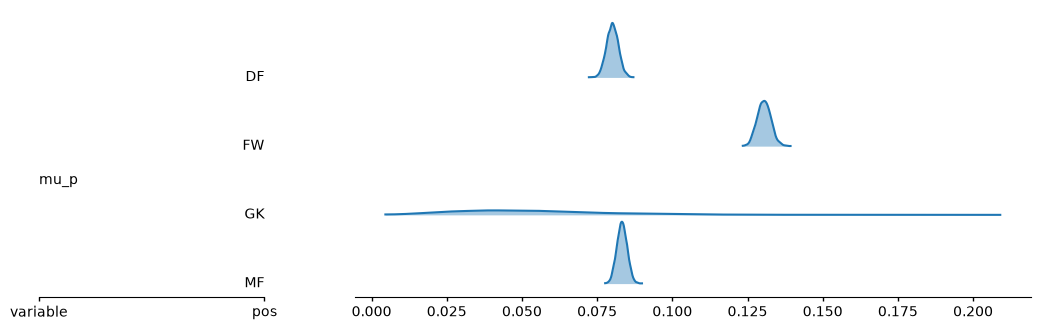

In [53]:
az.plot_ridge(
    idata_2,
    var_names=["mu_p"],
    combined=True,
)

-----------------------------

## Single player analytic model

If we want a personal model for (say) "Messi", we can get his shots and goals data, and update the prior (being the position's posterior) to give a new posterior just for him

In [54]:
goals = df[df["name"].str.endswith("Messi")].at[1457, "goals"]
shots = df[df["name"].str.endswith("Messi")].at[1457, "shots"]

We can get position _mu_ and _nu_ from the summary

In [55]:
summary = az.summary(idata_2)
summary

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_p[DF],0.08011,0.00197,0.077,0.083,5491,3165,1.00,2.7e-05,3.2e-05
mu_p[FW],0.13052,0.00225,0.13,0.13,5201,3045,1.00,3.1e-05,3.4e-05
mu_p[GK],0.0534,0.0259,0.019,0.099,4704,2852,1.00,0.00037,0.00048
mu_p[MF],0.08328,0.00171,0.081,0.086,5170,3186,1.00,2.4e-05,2.6e-05
nu_p[DF],107.8,20.4,80,140,4882,2797,1.00,0.31,0.4
nu_p[FW],71,7.3,60,83,5936,3443,1.00,0.096,0.12
nu_p[GK],125,49,59,210,4434,2831,1.00,0.71,0.76
nu_p[MF],89.2,11.4,72,110,4975,3070,1.00,0.16,0.18


Extract mean and concentration

In [56]:
fw_mu = summary.at["mu_p[FW]", "mean"]
fw_nu = summary.at["nu_p[FW]", "mean"]
fw_mu, fw_nu

(np.float64(0.13051707618306763), np.float64(70.9715379774395))

Convert to _alpha_, _beta_ 

In [57]:
fw_alpha, fw_beta = beta_mn_to_ab(fw_mu, fw_nu)

Update the _alpha_, _beta_ with the data from Messi goals from shots data, and plot the result,  He seems very consistent

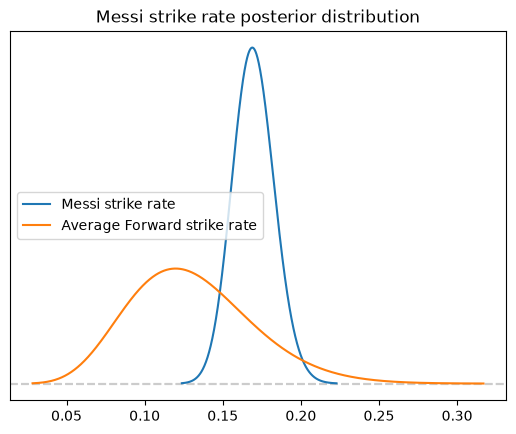

In [58]:
ax = pz.Beta(alpha=fw_alpha + goals, beta=fw_beta + shots - goals).plot_pdf()
pz.Beta(alpha=fw_alpha, beta=fw_beta).plot_pdf(ax=ax)
ax.set_title("Messi strike rate posterior distribution")

# Get the existing line/patch handles
handles, _ = ax.get_legend_handles_labels()

# better labels
new_labels = ["Messi strike rate", "Average Forward strike rate"]
ax.legend(handles=handles, labels=new_labels)

Update the mean and concentration values

In [59]:
post_mu, post_nu = beta_ab_to_mn(fw_alpha + goals, fw_beta + shots - goals)
post_mu, post_nu

(np.float64(0.16974441074371563), np.float64(790.9715379774395))

----------------------------

## Reproducibility

In [60]:
%load_ext watermark

In [61]:
%watermark

Last updated: 2026-10-13T14:46:08.441539+10:00

Python implementation: CPython
Python version       : 3.14.7
IPython version      : 9.17.1

Compiler    : MSC v.1944 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 170 Stepping 4, GenuineIntel
CPU cores   : 22
Architecture: 64bit



In [62]:
%watermark -h -iv -co

conda environment: bayes_env

Hostname: INSPIRON16

arviz     : 1.3.0
matplotlib: 3.11.1
numpy     : 2.4.6
pandas    : 3.0.5
preliz    : 0.28.0
pymc      : 6.3.1

